# HW2 Part 1: Data Cleaning & Validation of `ohlc_hw`

**Author:** Farshid Gilak

This notebook diagnoses and repairs the deliberately dirty `ohlc_hw` table, then saves the result as `ohlc_hw_cleaned` for the single-stock report (Part 2) and the batch runner (Part 3).

The work follows four rules from the assignment:

1. **Diagnose before repairing.** Every detector runs on the untouched data. The resulting *Data Quality Report* is kept, and the same detectors run again after cleaning.
2. **Repair only with evidence, and flag every repair.** Each estimated value has a flag. When a repair is not defensible, the row is quarantined with a reason rather than invented.
3. **Raw and adjusted prices obey different rules.** OHLC bounds apply to raw prices only. `adj_close` is checked through its adjustment factor `adj_close / close`.
4. **The source tables are never modified.** `ohlc_hw` and `ohlc` are read-only inputs. Outputs go to new tables in a *local working copy* of the database.

**Run order:** run this notebook top to bottom from a fresh kernel. It needs the bCourses `data.db`. On the first run it copies the database into `data/data.db` next to this notebook; that copy is gitignored.

| Section | Contents |
|---|---|
| 1.1 | Load and inspect |
| 1.2 | Detect issues and build the Data Quality Report |
| 1.2b | Investigate extreme returns |
| 1.3 | Clean, validate, save |
| 1.4 | Injected-fault tests for cases that are absent from this database |

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 120)
plt.style.use('seaborn-v0_8-whitegrid')

# Locate the repository root and this homework folder, whether Jupyter starts here or at the root.
course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
hw_dir = (Path.cwd() if (Path.cwd() / '01_data_cleaning.ipynb').is_file()
          else course_root / 'Homeworks/HW2/Farshid_Gilak')
db_path = hw_dir / 'data/data.db'   # "data/data.db" relative to the homework working directory

# Where the bCourses database may live. Lecture 4 is the documented location.
course_db_candidates = [course_root / 'Lectures/Lecture 4/data/data.db',
                        course_root / 'Lectures/Lecture 2/data/data.db']

### Local working copy

The assignment asks us to write cleaned tables to a local working copy, never to the course database. `ensure_working_copy` copies the bCourses file into `data/data.db` once, using SQLite's backup API on a read-only connection. Later runs reuse the copy, so rerunning the notebook simply replaces the output tables.

We also record a *fingerprint* of `ohlc_hw`: its row count and column totals. At the end we confirm that the raw table is unchanged.

In [2]:
def shown(path):
    # Repository-relative path for printing (keeps local absolute paths out of notebook output).
    return path.relative_to(course_root) if path.is_relative_to(course_root) else path


def ensure_working_copy(target, candidates):
    # Copy the course database to `target` once; the source is opened read-only.
    if target.is_file():
        print(f'Using existing working copy: {shown(target)}')
        return target
    source = next((p for p in candidates if p.is_file()), None)
    if source is None:
        raise FileNotFoundError('Download data.db from bCourses into Lectures/Lecture 4/data/ '
                                f'or place a copy at {target}')
    target.parent.mkdir(parents=True, exist_ok=True)
    with closing(sqlite3.connect(source.resolve().as_uri() + '?mode=ro', uri=True)) as src, \
         closing(sqlite3.connect(target)) as dst:
        src.backup(dst)
    print(f'Copied {shown(source)} -> {shown(target)}')
    return target


def table_fingerprint(conn, table):
    # Row count and column totals: cheap evidence that a table was not modified.
    query = f'SELECT COUNT(*), TOTAL(open), TOTAL(close), TOTAL(adj_close), TOTAL(volume) FROM {table}'
    return tuple(conn.execute(query).fetchone())


ensure_working_copy(db_path, course_db_candidates)
with closing(sqlite3.connect(db_path)) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn)
    raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)        # the dirty homework table
    reference = pd.read_sql_query('SELECT * FROM ohlc', conn)     # supplied reference (calendar + factors)
    raw_fingerprint = table_fingerprint(conn, 'ohlc_hw')
display(tables)
print(f'ohlc_hw: {len(raw):,} rows | ohlc (reference): {len(reference):,} rows')

Using existing working copy: Homeworks/HW2/Farshid_Gilak/data/data.db


,name
0,market_caps
1,ohlc
2,ohlc_hw
3,ohlc_hw_cleaned
4,ohlc_hw_outlier_review
5,ohlc_hw_quality_report
6,ohlc_hw_quarantine


ohlc_hw: 397,711 rows | ohlc (reference): 368,251 rows


## 1.1 Load and inspect the data

In [3]:
raw.info()
display(raw.describe().T)
display(raw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,count,mean,std,min,25%,50%,75%,max
open,397711.0,4.628548e+01,6.713259e+01,0.000000,4.209938e+00,19.85,57.53,6.042600e+02
high,397711.0,4.674766e+01,6.777821e+01,0.005208,4.240000e+00,20.06,58.13,6.086300e+02
low,397711.0,4.581628e+01,6.647718e+01,0.004801,4.160000e+00,19.63,56.95,5.978800e+02
close,397711.0,4.629290e+01,6.714188e+01,0.005208,4.200000e+00,19.86,57.53,6.054000e+02
adj_close,377856.0,5.165225e+01,1.945840e+02,0.002945,1.390000e+00,11.96,43.77,1.044251e+04
volume,397711.0,3.097773e+07,1.266237e+08,0.000000,1.730700e+06,4648200.00,11023796.50,9.276606e+09


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


### Columns and their meaning

| Column | Meaning | Checks that apply |
|---|---|---|
| `ts` | Observation (trading) date, stored as text `YYYY-MM-DD` | parseable date; one row per `(ticker, ts)` |
| `ticker` | Stock symbol as delivered by the vendor | must be normalized before grouping |
| `open`, `high`, `low`, `close` | **Raw** prices for the session, in dollars | finite, positive, `low <= open, close <= high` |
| `adj_close` | Vendor close adjusted for splits and distributions; use it for returns across corporate actions | finite, positive, and a smooth factor `adj_close / close`. Raw OHLC bounds do **not** apply. |
| `volume` | Shares traded | finite, nonnegative; zero may indicate a stale quote |

`.describe()` already shows some problems. `open` has a minimum of exactly 0, which is impossible for a traded equity. `adj_close` has fewer non-null values than the other columns, and its maximum (about 10,442) is far above the maximum raw `close` (605). An adjusted price should not normally exceed the raw price by that much.

In [4]:
dates = pd.to_datetime(raw['ts'], format='%Y-%m-%d', errors='coerce')
print(f"Date range: {dates.min().date()} to {dates.max().date()} | unparseable dates: {dates.isna().sum()}")
print(f"Distinct raw ticker labels: {raw['ticker'].nunique()}")
display(raw['ticker'].drop_duplicates().sample(6, random_state=1).to_frame('example raw labels'))

Date range: 1962-01-02 to 2024-12-06 | unparseable dates: 0
Distinct raw ticker labels: 150


,example raw labels
20,HON
965,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">UNH</span></a>"
568,"<a target=""_blank""><span style=""color: blue"">CVX</span></a>"
23,MMM
2166,"<a target=""_blank""><span style=""font-weight: bold; color: red"">WMT</span></a>"
265,"<a target=""_blank""><span style=""color: blue"">KO</span></a>"


The table has 150 distinct labels, but only 30 stocks. Most labels are wrapped in HTML (`<a><span style="color: red">AAPL</span></a>`). Grouping by the raw label would split every stock into five fragments. `normalize_ticker` removes tags and whitespace and converts the label to uppercase. `prepare` applies it, parses `ts`, and keeps the original label in `raw_ticker` for the audit trail. It changes **no values**.

In [5]:
PRICE_COLS = ['open', 'high', 'low', 'close']        # raw prices: OHLC bounds apply
ALL_PRICE_COLS = PRICE_COLS + ['adj_close']          # adjusted close: positivity + factor consistency
VALUE_COLS = ['ticker', 'ts', *ALL_PRICE_COLS, 'volume']
KEY = ['ticker', 'ts']
ISSUE_COLUMNS = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']
N_STD = 3.0                 # return-screen threshold in sample standard deviations
FACTOR_WINDOW = 11          # sessions in the centred window used to judge an adjustment factor
FACTOR_TOLERANCE = 0.10     # a factor more than 10% away from its neighbours is inconsistent
BRACKET_TOLERANCE = 0.005   # neighbouring factors that agree within 0.5% imply no corporate action


def normalize_ticker(labels):
    # '<a><span style="color: red"> aapl </span></a>' -> 'AAPL'
    return (labels.astype('string')
            .str.replace(r'<[^>]+>', '', regex=True)
            .str.strip()
            .str.upper())


def prepare(frame):
    # Normalize labels and types without changing any values; keep the original label.
    out = frame.copy()
    out['raw_ticker'] = out['ticker']
    out['ticker'] = normalize_ticker(out['ticker'])
    out['ts'] = pd.to_datetime(out['ts'], format='%Y-%m-%d', errors='coerce')
    numeric = ALL_PRICE_COLS + ['volume']
    out[numeric] = out[numeric].apply(pd.to_numeric, errors='coerce').astype(float)
    return out


prepared = prepare(raw)
label_audit = (prepared.groupby(['ticker', 'raw_ticker']).size()
               .rename('rows').reset_index())
print('Normalized tickers:', prepared['ticker'].nunique())
print(sorted(prepared['ticker'].unique()))
display(label_audit.loc[label_audit['ticker'] == 'AAPL'])

Normalized tickers: 30
['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ticker,raw_ticker,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",264
4,AAPL,AAPL,10747


In [6]:
coverage = (prepared.groupby('ticker')
            .agg(rows=('ts', 'size'), first_date=('ts', 'min'), last_date=('ts', 'max')))
display(coverage.T)
print('Supplied histories end on different dates:', coverage['last_date'].dt.date.unique())

ticker,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,GS,HD,HON,IBM,JNJ,JPM,KO,MCD,MMM,MRK,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
rows,11942,11290,7458,14260,16980,17044,5525,9427,17073,17151,6931,11731,17111,17138,17097,15145,17147,15830,17041,17111,10486,11989,7030,17108,15470,14325,10909,4516,11151,14295
first_date,1980-12-12 00:00:00,1983-06-17 00:00:00,1997-05-15 00:00:00,1972-04-03 00:00:00,1962-01-02 00:00:00,1962-01-02 00:00:00,2004-06-23 00:00:00,1990-02-16 00:00:00,1962-01-02 00:00:00,1962-01-02 00:00:00,1999-05-04 00:00:00,1981-09-22 00:00:00,1962-01-02 00:00:00,1962-01-02 00:00:00,1962-01-02 00:00:00,1969-03-05 00:00:00,1962-01-02 00:00:00,1966-07-05 00:00:00,1962-01-02 00:00:00,1962-01-02 00:00:00,1986-03-13 00:00:00,1980-12-02 00:00:00,1999-01-22 00:00:00,1962-01-02 00:00:00,1968-01-02 00:00:00,1972-04-03 00:00:00,1984-10-17 00:00:00,2008-03-19 00:00:00,1983-11-21 00:00:00,1972-04-03 00:00:00
last_date,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-12-06 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00,2024-10-18 00:00:00


Supplied histories end on different dates: [datetime.date(2024, 10, 18) datetime.date(2024, 12, 6)]


## 1.2 Detect data quality issues

Each detector returns rows in the Data Quality Report format:

`ticker | issue_type | issue_date | description | severity`

There is one row per affected observation. An observation can carry several issues; for example, a zero open is both a `nonpositive_price` and an `open_outside_range`.

### Severity scale

| Severity | Meaning | Issue types |
|---|---|---|
| **high** | The value is impossible or unknown and would corrupt returns or risk metrics if used | missing or invalid prices, OHLC-bound violations, an inconsistent or mismatched `adj_close`, conflicting duplicate keys, invalid dates, negative or non-finite volume |
| **medium** | The data may be valid but needs review, or it distorts statistics if left alone | missing trading days, exact duplicates (they double-weight a day), missing volume, extreme returns (a review flag), zero volume on a flat bar (a possible stale quote) |
| **low** | Cosmetic or explained, with a deterministic fix | ticker label markup, zero volume on a bar that has a price range |

Severity describes the risk *before* investigation. The investigation in 1.2b records what each extreme return turned out to be.

In [7]:
def concat_issues(parts):
    # Concatenate issue tables, skipping empty ones (an empty report keeps its columns).
    parts = [p for p in parts if not p.empty]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=ISSUE_COLUMNS)


def issue_rows(frame, mask, issue_type, severity, description):
    # One report row per flagged observation. `description` is a string or a function of the flagged rows.
    flagged = frame.loc[mask]
    rows = flagged[['ticker', 'ts']].rename(columns={'ts': 'issue_date'})
    rows['issue_type'] = issue_type
    rows['description'] = description(flagged) if callable(description) else description
    rows['severity'] = severity
    return rows[ISSUE_COLUMNS]


def ohlc_text(f):
    return [f'O={o:.6g} H={h:.6g} L={l:.6g} C={c:.6g}'
            for o, h, l, c in zip(f['open'], f['high'], f['low'], f['close'])]


def detect_label_issues(frame):
    return issue_rows(frame, frame['raw_ticker'].ne(frame['ticker']), 'ticker_label_markup', 'low',
                      lambda f: [f'Raw label {r!r} normalized to {t}' for r, t in zip(f['raw_ticker'], f['ticker'])])


def detect_invalid_dates(frame):
    return issue_rows(frame, frame['ts'].isna(), 'invalid_date', 'high', 'ts is not a valid YYYY-MM-DD date')


def detect_duplicates(frame):
    # Exact copies are removable; same key with different values cannot be resolved by picking one.
    exact = frame.duplicated(VALUE_COLS, keep='first')
    distinct = frame.loc[~exact]
    conflict = distinct.duplicated(KEY, keep=False) & distinct['ts'].notna()
    return concat_issues([
        issue_rows(frame, exact, 'exact_duplicate', 'medium', 'Exact copy of an earlier row (after label normalization)'),
        issue_rows(distinct, conflict, 'conflicting_duplicate_key', 'high',
                   'Same (ticker, ts) delivered with different values; source cannot be chosen'),
    ])


def missing_value_summary(frame):
    cols = ALL_PRICE_COLS + ['volume']
    return pd.DataFrame({'missing': frame[cols].isna().sum(),
                         'non_finite': np.isinf(frame[cols]).sum(),
                         'pct_missing': (frame[cols].isna().mean() * 100).round(3)})


def detect_missing_values(frame):
    severity = {col: 'high' for col in ALL_PRICE_COLS} | {'volume': 'medium'}
    parts = [issue_rows(frame, frame[col].isna(), f'missing_{col}', sev, f'{col} is missing')
             for col, sev in severity.items()]
    parts.append(issue_rows(frame, frame[PRICE_COLS].isna().all(axis=1), 'missing_all_raw_prices', 'high',
                            'open, high, low and close are all missing'))
    return concat_issues(parts)

### Missing trading days

`.isna()` finds missing values in rows that exist. It cannot detect a row that is absent altogether. For that we need an **expected calendar**.

**Calendar assumption.** As the assignment allows, each ticker's expected sessions are its dates in the supplied `ohlc` table, over that ticker's own supplied history. Business weekdays would wrongly expect exchange holidays, and a market-wide calendar would wrongly expect sessions before a listing date. The check therefore shows that `ohlc_hw` is complete *relative to the vendor's history*. It does not certify completeness against the exchange. We report absent dates and do not invent prices for them.

In [8]:
def missing_sessions(frame, expected_dates):
    # Expected dates that are absent from one ticker's observations.
    observed = pd.DatetimeIndex(frame['ts'].dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()


def detect_missing_days(frame, calendar):
    # Compare each ticker with its own reference sessions; returns (issue rows, per-ticker summary).
    observed_by_ticker = dict(tuple(frame.groupby('ticker')))
    parts, summary = [], []
    for ticker, expected in calendar.groupby('ticker')['ts']:
        observed = observed_by_ticker.get(ticker, frame.iloc[0:0])
        gaps = missing_sessions(observed, expected)
        extra = pd.DatetimeIndex(observed['ts'].dropna().unique()).difference(pd.DatetimeIndex(expected))
        start, end = expected.min(), expected.max()
        summary.append({'ticker': ticker, 'expected_sessions': expected.nunique(),
                        'observed_sessions': observed['ts'].nunique(), 'missing_days': len(gaps),
                        'dates_not_in_calendar': len(extra),
                        'summary': f'Ticker {ticker} is missing {len(gaps)} trading days '
                                   f'between {start:%Y-%m-%d} and {end:%Y-%m-%d}'})
        parts.append(pd.DataFrame({'ticker': ticker, 'issue_date': gaps, 'issue_type': 'missing_trading_day',
                                   'description': 'No row for this session in the reference calendar',
                                   'severity': 'medium'}))
        parts.append(pd.DataFrame({'ticker': ticker, 'issue_date': extra, 'issue_type': 'date_not_in_calendar',
                                   'description': 'Row dated on a session absent from the reference calendar',
                                   'severity': 'medium'}))
    unknown = sorted(set(observed_by_ticker) - set(calendar['ticker']))
    for ticker in unknown:
        summary.append({'ticker': ticker, 'summary': f'Ticker {ticker} has no reference calendar'})
    return concat_issues(parts)[ISSUE_COLUMNS], pd.DataFrame(summary)

**Detector demo with one deliberately removed date.** The supplied calendar has four sessions. DEMO_A's delivery omits January 3, and the detector must find exactly that date. A complete delivery must produce zero gaps.

In [9]:
demo_sessions = pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'])
demo_calendar = pd.DataFrame({'ticker': 'DEMO_A', 'ts': demo_sessions})
demo_delivery = demo_calendar.drop(index=1)                      # remove 2024-01-03
demo_gap_rows, demo_gap_summary = detect_missing_days(demo_delivery, demo_calendar)
print(demo_gap_summary.loc[0, 'summary'])
display(demo_gap_rows)
assert demo_gap_rows['issue_date'].tolist() == [pd.Timestamp('2024-01-03')]
assert detect_missing_days(demo_calendar, demo_calendar)[1].loc[0, 'missing_days'] == 0

Ticker DEMO_A is missing 1 trading days between 2024-01-02 and 2024-01-05


,ticker,issue_type,issue_date,description,severity
0,DEMO_A,missing_trading_day,2024-01-03,No row for this session in the reference calendar,medium


### Invalid prices, OHLC bounds, and volume

- **Nonpositive or non-finite prices** are checked for all five price columns, including `adj_close`.
- **OHLC bounds** (`low <= open <= high`, `low <= close <= high`) apply to raw prices only. `high_below_close` and `low_above_close` are the "impossible" closes named in the assignment.
- **Zero volume** can indicate a stale, carried-forward quote. It is more suspicious when the bar is flat (`O = H = L = C`), meaning that no price discovery happened either.

In [10]:
def detect_invalid_prices(frame):
    parts = []
    for col in ALL_PRICE_COLS:
        values = frame[col]
        parts.append(issue_rows(frame, values.notna() & ~np.isfinite(values), 'nonfinite_price', 'high',
                                lambda f, c=col: [f'{c} = {v}' for v in f[c]]))
        parts.append(issue_rows(frame, values.le(0), 'nonpositive_price', 'high',
                                lambda f, c=col: [f'{c} = {v:g}; equity prices must be positive' for v in f[c]]))
    return concat_issues(parts)


def detect_ohlc_violations(frame):
    o, h, l, c = (frame[col] for col in PRICE_COLS)
    checks = {
        'high_below_close': (h < c, 'high is below close'),
        'low_above_close': (l > c, 'low is above close'),
        'open_outside_range': ((o < l) | (o > h), 'open is outside [low, high]'),
        'high_below_low': (h < l, 'high is below low'),
    }
    return concat_issues([issue_rows(frame, mask, name, 'high',
                                 lambda f, text=text: [f'{text}: {v}' for v in ohlc_text(f)])
                      for name, (mask, text) in checks.items()])


def detect_volume_issues(frame):
    v = frame['volume']
    flat = frame['high'].eq(frame['low']) & frame['open'].eq(frame['high']) & frame['close'].eq(frame['high'])
    zero = v.eq(0)
    return concat_issues([
        issue_rows(frame, np.isinf(v) | v.lt(0), 'invalid_volume', 'high',
                   lambda f: [f'volume = {x}; must be finite and nonnegative' for x in f['volume']]),
        issue_rows(frame, zero & flat, 'zero_volume', 'medium',
                   'Zero volume on a flat bar (O=H=L=C): possible stale or carried-forward quote'),
        issue_rows(frame, zero & ~flat, 'zero_volume', 'low',
                   'Zero volume although the bar has a price range: volume probably unrecorded'),
    ])

### Extreme returns

Daily return: `(close - prev_close) / prev_close`, computed **within each ticker** after sorting by date. A row is flagged when

$$|r_t - \bar r| > 3\,s, \qquad s = \text{sample standard deviation } (\text{ddof}=1),$$

using that ticker's own mean and standard deviation. Both tails are flagged.

- **Undefined returns are excluded.** These are the first observation and any return whose current or previous close is missing, nonpositive, or non-finite.
- **Zero or undefined `s`.** A constant series, or one with fewer than two returns, has no meaningful z-score. The ticker gets **no** statistical flags, and the screen summary says so explicitly instead of dividing by zero.
- **This is a review flag, not a deletion rule.** It is retrospective: it uses the full history, so it describes the data and is not a trading signal.

In [11]:
def return_outlier_screen(frame, price_col='close', n_std=N_STD):
    # Two-tailed |r - mean| > n_std * sample std within each ticker. Frame must be sorted with unique keys.
    price = frame[price_col].where(np.isfinite(frame[price_col]) & frame[price_col].gt(0))
    prev = price.groupby(frame['ticker']).shift(1)
    ret = (price - prev) / prev
    grouped = ret.groupby(frame['ticker'])
    mean = grouped.transform('mean')
    std = grouped.transform(lambda s: s.std(ddof=1))
    usable = np.isfinite(std) & std.gt(0)                 # zero/undefined std -> no statistical flags
    z = (ret - mean) / std.where(usable)
    flag = ret.notna() & usable & (ret - mean).abs().gt(n_std * std)
    return pd.DataFrame({'return': ret, 'z_score': z, 'return_flag': flag}, index=frame.index)


def screen_summary(frame, screen):
    stats = screen.groupby(frame['ticker']).agg(returns=('return', 'count'), mean=('return', 'mean'),
                                                std=('return', lambda s: s.std(ddof=1)),
                                                flagged=('return_flag', 'sum'))
    usable = np.isfinite(stats['std']) & stats['std'].gt(0)
    stats['status'] = np.where(usable, 'screened', 'std zero/undefined: no statistical flags')
    return stats

### `adj_close` consistency (reference-free detector)

The raw `close` in this vendor feed is already split-adjusted. The factor `adj_close / close` therefore changes only through dividends and distributions: small **steps** that persist. A single day whose factor is far from its neighbours is not a corporate action. Either that day's `adj_close` or its `close` is wrong.

`factor_spikes` compares each factor with the **median of a centred 11-session window** of the same ticker. A median ignores a few bad neighbours, and on either side of a genuine step the majority of the window shares the row's level, so steps are not flagged. Deviations above 10% are flagged.

We then **verify** against the reference separately. `compare_with_reference` compares `close` and `adj_close` with the matching `(ticker, ts)` row in `ohlc`. This second, independent detector shows how well the first one works.

In [12]:
def factor_spikes(frame, window=FACTOR_WINDOW, tolerance=FACTOR_TOLERANCE):
    # Flag adj_close/close factors that depart > tolerance from the centred rolling median (sorted frame).
    factor = frame['adj_close'] / frame['close']
    factor = factor.where(np.isfinite(factor) & factor.gt(0))
    local = factor.groupby(frame['ticker']).transform(
        lambda s: s.rolling(window, center=True, min_periods=3).median())
    deviation = factor / local - 1
    return pd.DataFrame({'factor': factor, 'factor_deviation': deviation,
                         'factor_spike': deviation.abs().gt(tolerance)}, index=frame.index)


def reference_evidence(reference_table):
    # Per (ticker, ts) in the reference: factor, whether it is trustworthy, its step, and adjusted-return screen.
    ref = prepare(reference_table).sort_values(KEY).reset_index(drop=True)
    assert not ref.duplicated(KEY).any(), 'The reference must have unique (ticker, ts) keys'
    spikes = factor_spikes(ref)
    by_ticker = spikes['factor'].groupby(ref['ticker'])
    adj_screen = return_outlier_screen(ref, 'adj_close')
    return pd.DataFrame({
        'ticker': ref['ticker'], 'ts': ref['ts'],
        'ref_close': ref['close'], 'ref_adj_close': ref['adj_close'], 'ref_factor': spikes['factor'],
        'ref_factor_trusted': spikes['factor'].notna() & ~spikes['factor_spike'],
        'ref_factor_spike': spikes['factor_spike'],
        'ref_factor_step': spikes['factor'] / by_ticker.shift(1) - 1,
        'ref_factor_next_step': by_ticker.shift(-1) / spikes['factor'] - 1,
        'ref_adj_return': adj_screen['return'], 'ref_adj_return_flag': adj_screen['return_flag'],
    })


def attach_reference(frame, evidence):
    # Reference columns aligned to frame's index (left join on ticker and date).
    merged = frame[KEY].merge(evidence, on=KEY, how='left', validate='many_to_one')
    merged.index = frame.index
    return merged.drop(columns=KEY)


def compare_with_reference(frame, ref):
    close_mismatch = (ref['ref_close'].notna() & frame['close'].notna()
                      & ~np.isclose(frame['close'], ref['ref_close'], rtol=1e-9))
    adj_mismatch = (ref['ref_adj_close'].notna() & frame['adj_close'].notna()
                    & ~np.isclose(frame['adj_close'], ref['ref_adj_close'], rtol=1e-6))
    both = frame.assign(ref_close=ref['ref_close'], ref_adj_close=ref['ref_adj_close'])
    return concat_issues([
        issue_rows(both, close_mismatch, 'close_mismatch_reference', 'high',
                   lambda f: [f'close {a:.6g} vs reference {b:.6g}' for a, b in zip(f['close'], f['ref_close'])]),
        issue_rows(both, adj_mismatch, 'adj_close_mismatch_reference', 'high',
                   lambda f: [f'adj_close {a:.6g} vs reference {b:.6g} (x{a / b:.2f})'
                              for a, b in zip(f['adj_close'], f['ref_adj_close'])]),
    ])

### Building the Data Quality Report

`diagnose` runs every detector on the prepared (normalized but **unrepaired**) data:

1. It runs the label, date, and duplicate checks on all rows.
2. It runs the value checks (missing, invalid, bounds, volume) and the calendar check on the de-duplicated rows.
3. It runs the return screen and the factor detector on a frame sorted by `ticker, ts` with unique keys. Returns cannot be computed across duplicate or conflicting rows.

In [13]:
def diagnose(frame, evidence):
    # Run every detector on unrepaired data. Returns (issue report, sorted unique frame with screens, gap summary).
    calendar = evidence[KEY]
    distinct = frame.loc[~frame.duplicated(VALUE_COLS)]
    conflict = distinct.duplicated(KEY, keep=False)
    unique = distinct.loc[~conflict & distinct['ts'].notna()].sort_values(KEY).reset_index(drop=True)

    gap_issues, gap_summary = detect_missing_days(distinct, calendar)
    unique = pd.concat([unique, return_outlier_screen(unique), factor_spikes(unique)], axis=1)
    parts = [
        detect_label_issues(frame), detect_invalid_dates(frame), detect_duplicates(frame),
        detect_missing_values(distinct), gap_issues, detect_invalid_prices(distinct),
        detect_ohlc_violations(distinct), detect_volume_issues(distinct),
        issue_rows(unique, unique['return_flag'], 'extreme_return', 'medium',
                   lambda f: [f'Close-to-close return {r:+.2%} (z = {z:+.1f}); review flag, not a deletion rule'
                              for r, z in zip(f['return'], f['z_score'])]),
        issue_rows(unique, unique['factor_spike'], 'adj_close_factor_spike', 'high',
                   lambda f: [f'adj_close/close = {x:.4g} departs {d:+.0%} from neighbouring factors'
                              for x, d in zip(f['factor'], f['factor_deviation'])]),
        compare_with_reference(unique, attach_reference(unique, evidence)),
    ]
    report = (concat_issues(parts)
              .sort_values(['ticker', 'issue_date', 'issue_type'], kind='stable').reset_index(drop=True))
    return report, unique, gap_summary


evidence = reference_evidence(reference)
quality_report, unique, gap_summary = diagnose(prepared, evidence)
print(f'Data Quality Report: {len(quality_report):,} issue rows '
      f'on {quality_report[["ticker", "issue_date"]].drop_duplicates().shape[0]:,} distinct observations')
display(quality_report.head(10))

Data Quality Report: 113,751 issue rows on 91,325 distinct observations


,ticker,issue_type,issue_date,description,severity
0,AAPL,ticker_label_markup,1980-12-19,"Raw label '<a target=""_blank""><span style=""color: red"">AAPL</span></a>' normalized to AAPL",low
1,AAPL,extreme_return,1980-12-26,"Close-to-close return +9.23% (z = +3.3); review flag, not a deletion rule",medium
2,AAPL,ticker_label_markup,1980-12-29,"Raw label '<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>' normalized to AAPL",low
3,AAPL,exact_duplicate,1981-01-02,Exact copy of an earlier row (after label normalization),medium
4,AAPL,exact_duplicate,1981-01-05,Exact copy of an earlier row (after label normalization),medium
5,AAPL,missing_adj_close,1981-01-08,adj_close is missing,high
6,AAPL,missing_adj_close,1981-01-13,adj_close is missing,high
7,AAPL,ticker_label_markup,1981-02-02,"Raw label '<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>' normalized to AAPL",low
8,AAPL,adj_close_factor_spike,1981-02-03,adj_close/close = 10.25 departs +1230% from neighbouring factors,high
9,AAPL,adj_close_mismatch_reference,1981-02-03,adj_close 1.26459 vs reference 0.0950693 (x13.30),high


### What the diagnosis found

In [14]:
issue_counts = (quality_report.groupby(['issue_type', 'severity']).size().rename('rows')
                .reset_index().sort_values('rows', ascending=False).reset_index(drop=True))
display(issue_counts)

print('Missing values per column (all rows, before de-duplication):')
display(missing_value_summary(prepared))

,issue_type,severity,rows
0,ticker_label_markup,low,39936
1,exact_duplicate,medium,29460
2,missing_adj_close,high,18374
3,adj_close_factor_spike,high,10423
4,adj_close_mismatch_reference,high,10417
5,extreme_return,medium,5056
6,zero_volume,medium,72
7,nonpositive_price,high,5
8,open_outside_range,high,5
9,zero_volume,low,3


Missing values per column (all rows, before de-duplication):


,missing,non_finite,pct_missing
open,0,0,0.000
high,0,0,0.000
low,0,0,0.000
close,0,0,0.000
adj_close,19855,0,4.992
volume,0,0,0.000


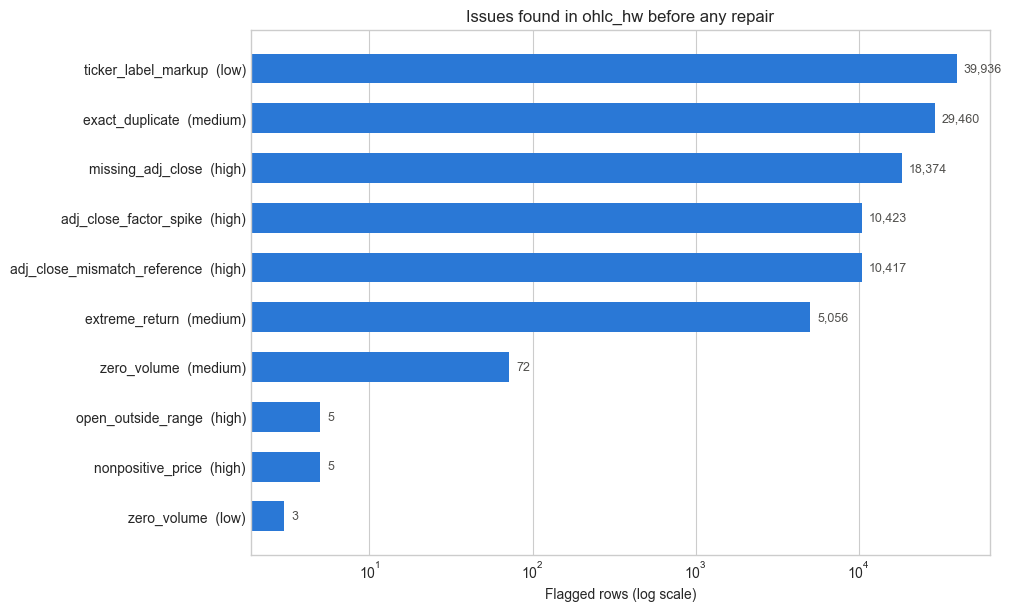

In [15]:
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
plot_counts = issue_counts.sort_values('rows')
labels = [f'{t}  ({s})' for t, s in zip(plot_counts['issue_type'], plot_counts['severity'])]
ax.barh(labels, plot_counts['rows'], color='#2a78d6', height=0.6)
ax.set_xscale('log')
for y, value in enumerate(plot_counts['rows']):
    ax.text(value * 1.1, y, f'{value:,}', va='center', fontsize=9, color='#52514e')
ax.set(title='Issues found in ohlc_hw before any repair', xlabel='Flagged rows (log scale)')
ax.grid(axis='y', visible=False)
plt.show()

In [16]:
print('\n'.join(gap_summary['summary']))
assert gap_summary['missing_days'].sum() == 0 and gap_summary['dates_not_in_calendar'].sum() == 0

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

**Missing trading days: zero.** After normalization and de-duplication, every ticker has exactly the sessions in its reference history. A correct check is allowed to find nothing, so we report zero rather than invent gaps. The detector itself was demonstrated above on a deliberately removed date.

**Summary of the diagnosis:**

- **Ticker labels.** Four HTML variants plus the plain label for each of the 30 stocks.
- **Exact duplicates.** 29,460 rows. Once they are removed, the table has exactly the reference row count, and there are **no conflicting `(ticker, ts)` keys**.
- **`adj_close` is the main data error.** About 18k values are missing. Around 10.4k more are inflated by a factor of 4–24×. The reference-free factor detector and the reference cross-check agree on those rows almost perfectly (compared below).
- **Raw OHLC and volume agree with the reference exactly** (`close_mismatch_reference` = 0). The raw-price issues below therefore come from the vendor's history itself:
  - 5 rows have `open = 0`, each on the ticker's first date in 1962–1966.
  - 75 zero-volume days, most of them flat bars.
- **No missing raw prices, no missing volume, no non-finite values, and no `high < close` or `low > close` rows.** These required cases are absent from this database. Section 1.4 injects each one into a small synthetic dataset and tests the same detectors and repairs.

In [17]:
factor_flag = unique['factor_spike']
adj_mismatch_keys = quality_report.loc[quality_report['issue_type'] == 'adj_close_mismatch_reference', ['ticker', 'issue_date']]
mismatch = unique.set_index(KEY).index.isin(pd.MultiIndex.from_frame(adj_mismatch_keys))
agreement = pd.crosstab(pd.Series(factor_flag, name='factor detector flags'),
                        pd.Series(mismatch, name='differs from reference'))
display(agreement)
vendor_shared = unique.loc[factor_flag & ~mismatch, ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'factor_deviation']]
print('Factor spikes where ohlc_hw equals the reference (the vendor history itself is inconsistent):')
display(vendor_shared)

differs from reference,False,True
factor detector flags,,
False,357828,0
True,6,10417


Factor spikes where ohlc_hw equals the reference (the vendor history itself is inconsistent):


,ticker,ts,open,high,low,close,adj_close,volume,factor_deviation
2486,AAPL,1990-10-19,0.28000,0.28000,0.27000,0.28000,0.280000,933733760.0,0.256054
197570,KO,1962-01-02,0.26302,0.27018,0.26302,0.26302,0.048145,806400.0,-0.204933
269637,NKE,1981-08-10,0.15234,0.15234,0.15234,0.15234,0.107230,0.0,0.262257
306420,SHW,1982-02-12,0.39323,0.39323,0.39323,0.39323,0.206950,0.0,0.115402
318873,TRV,1978-12-20,8.03000,8.03000,8.03000,8.03000,2.800000,0.0,0.523269
319538,TRV,1981-08-10,12.06000,12.06000,12.06000,12.06000,4.200000,0.0,0.339109


The reference-free detector catches every corrupted `adj_close`. It also flags a handful of rows where `ohlc_hw` **equals** the reference. On those dates the vendor's own history is internally inconsistent. Several are zero-volume flat bars on which the raw close jumps for one day (TRV), and others are one-day factor glitches (AAPL 1990-10-19). Copying the reference factor would simply copy the glitch. The repair therefore uses a reference factor only after the reference passes the same consistency test.

## 1.2b Investigating extreme returns

The assignment asks whether each extreme return is a split, a corporate action, a data error, or a genuine move. We classify every flagged return from evidence in the data. A cause is never assumed.

| Class | Evidence required | Action |
|---|---|---|
| `confirmed_data_error` | (1) the price jumps and **reverses the next day**, with the close returning near its prior level; (2) **zero volume** that day, so no trade supports the print; (3) the vendor's adjustment factor is **inconsistent** that day, in `ohlc_hw` or the reference | Interpolate OHLC (and the factor) between the valid neighbours |
| `error_reversal` | The flagged return is the bounce back from a confirmed error on the previous day | Resolved by the previous day's repair |
| `distribution` | The raw close moves but the **adjusted** return is normal, because the reference factor **steps and the step persists** | Keep the raw price; returns should use `adj_close` |
| `suspicious_zero_volume` | A one-day reversal on zero volume with no independent corroboration | Keep; flag for vendor confirmation |
| `market_move` | Anything else: a traded move that the vendor's adjusted series shows as well | Keep and flag. The cause (news, crash, earnings) **cannot be verified** from prices alone. |

Splits do not appear as a separate class because this feed's raw `close` is already split-adjusted. A split would show up as a persistent factor step and fall under `distribution`.

In [18]:
def investigate_extreme_returns(unique, evidence):
    # Classify each flagged close-to-close return from reversal, volume and adjustment-factor evidence.
    d = unique
    ref = attach_reference(d, evidence)
    by_ticker = d.groupby('ticker')
    prev_close, next_close = by_ticker['close'].shift(1), by_ticker['close'].shift(-1)
    next_return = by_ticker['return'].shift(-1)
    through = next_close / prev_close - 1          # net move across the two days
    reversal = (next_return.notna() & np.sign(next_return).eq(-np.sign(d['return']))
                & through.abs().lt(0.25 * d['return'].abs()))
    zero_volume = d['volume'].eq(0)
    factor_inconsistent = d['factor_spike'] | ref['ref_factor_spike'].eq(True)
    step_persists = (ref['ref_factor_step'].abs().gt(BRACKET_TOLERANCE)
                     & ref['ref_factor_next_step'].abs().lt(BRACKET_TOLERANCE))

    flagged = d['return_flag']
    confirmed = flagged & reversal & zero_volume & factor_inconsistent
    after_error = flagged & ~confirmed & confirmed.groupby(d['ticker']).shift(1, fill_value=False)
    distribution = (flagged & ~confirmed & ~after_error & ref['ref_adj_return_flag'].eq(False) & step_persists)
    suspicious = flagged & ~(confirmed | after_error | distribution) & reversal & zero_volume
    classes = np.select([confirmed, after_error, distribution, suspicious, flagged],
                        ['confirmed_data_error', 'error_reversal', 'distribution', 'suspicious_zero_volume',
                         'market_move'], default='')
    actions = {'confirmed_data_error': 'repair: interpolate OHLC between neighbours',
               'error_reversal': 'resolved by prior-day repair',
               'distribution': 'keep (corporate action)',
               'suspicious_zero_volume': 'keep, flag for vendor review',
               'market_move': 'keep, flag'}

    review = d.loc[flagged, ['ticker', 'ts', 'close', 'volume', 'return', 'z_score']].copy()
    review['classification'] = classes[flagged.to_numpy()]
    review['action'] = review['classification'].map(actions)
    rows = pd.concat([review.rename(columns={'return': 'ret'}), through.loc[flagged].rename('through'),
                      ref.loc[flagged]], axis=1)
    review['evidence'] = [_evidence_text(row) for row in rows.itertuples()]
    return review.reset_index(drop=True)


def _evidence_text(row):
    r = row.ret
    if row.classification == 'confirmed_data_error':
        return (f'{r:+.1%} one-day jump on zero volume reverses next day (two-day net {row.through:+.1%}); '
                'adjustment factor inconsistent on this date -> data error')
    if row.classification == 'error_reversal':
        return 'Bounce back from the previous day\'s confirmed data error'
    if row.classification == 'distribution':
        return (f'Raw close {r:+.1%}, but the reference factor steps {row.ref_factor_step:+.1%} and persists; '
                f'adjusted return {row.ref_adj_return:+.1%} is normal -> dividend/distribution ex-date')
    if row.classification == 'suspicious_zero_volume':
        return f'{r:+.1%} move on zero volume that reverses next day; no independent corroboration'
    text = (f'Traded move (volume {row.volume:,.0f}); vendor adjusted return {row.ref_adj_return:+.1%}; '
            'cause not verifiable from prices')
    if abs(r) >= 0.5:
        text += '; very large persistent move: possibly an unadjusted split in the vendor history, or news'
    return text


outlier_review = investigate_extreme_returns(unique, evidence)
print(f'Flagged returns: {len(outlier_review):,} of {unique["return"].notna().sum():,} defined returns')
display(outlier_review['classification'].value_counts().rename('rows').to_frame())
display(screen_summary(unique, unique[['return', 'return_flag']]).head(5))

Flagged returns: 5,056 of 368,221 defined returns


,rows
classification,
market_move,5027
distribution,22
confirmed_data_error,3
error_reversal,3
suspicious_zero_volume,1


,returns,mean,std,flagged,status
ticker,,,,,
AAPL,11049,0.001074,0.027846,143,screened
AMGN,10420,0.000937,0.023731,172,screened
AMZN,6936,0.001729,0.035298,147,screened
AXP,13251,0.000577,0.022122,199,screened
BA,15783,0.000561,0.021421,210,screened


In [19]:
for cls in ['confirmed_data_error', 'error_reversal', 'distribution', 'suspicious_zero_volume']:
    print(cls)
    display(outlier_review.loc[outlier_review['classification'] == cls].head(8))
print('Largest market moves (kept):')
moves = outlier_review.loc[outlier_review['classification'] == 'market_move']
display(moves.loc[moves['return'].abs().sort_values(ascending=False).index].head(8))

confirmed_data_error


,ticker,ts,close,volume,return,z_score,classification,action,evidence
4425,TRV,1976-10-28,9.22,0.0,1.000000,41.244530,confirmed_data_error,repair: interpolate OHLC between neighbours,+100.0% one-day jump on zero volume reverses next day (two-day net +1.7%); adjustment factor inconsistent on this da...
4427,TRV,1978-12-20,8.03,0.0,0.997512,41.141873,confirmed_data_error,repair: interpolate OHLC between neighbours,+99.8% one-day jump on zero volume reverses next day (two-day net +1.7%); adjustment factor inconsistent on this dat...
4429,TRV,1981-08-10,12.06,0.0,1.000000,41.244530,confirmed_data_error,repair: interpolate OHLC between neighbours,+100.0% one-day jump on zero volume reverses next day (two-day net +0.0%); adjustment factor inconsistent on this da...


error_reversal


,ticker,ts,close,volume,return,z_score,classification,action,evidence
4426,TRV,1976-10-29,4.69,79200.0,-0.491323,-20.299686,error_reversal,resolved by prior-day repair,Bounce back from the previous day's confirmed data error
4428,TRV,1978-12-21,4.09,105600.0,-0.490660,-20.272317,error_reversal,resolved by prior-day repair,Bounce back from the previous day's confirmed data error
4430,TRV,1981-08-11,6.03,24800.0,-0.500000,-20.657761,error_reversal,resolved by prior-day repair,Bounce back from the previous day's confirmed data error


distribution


,ticker,ts,close,volume,return,z_score,classification,action,evidence
222,AMGN,1990-02-15,1.16000,26539464.0,0.074074,3.081888,distribution,keep (corporate action),"Raw close +7.4%, but the reference factor steps -0.6% and persists; adjusted return +6.7% is normal -> dividend/dist..."
1204,CSCO,1994-11-11,1.83000,202203000.0,0.076471,3.031721,distribution,keep (corporate action),"Raw close +7.6%, but the reference factor steps -0.6% and persists; adjusted return +7.0% is normal -> dividend/dist..."
1368,CVX,1982-02-01,8.63000,1350000.0,-0.054765,-3.406702,distribution,keep (corporate action),"Raw close -5.5%, but the reference factor steps +1.6% and persists; adjusted return -4.0% is normal -> dividend/dist..."
1372,CVX,1982-07-14,6.91000,2615200.0,0.053354,3.273296,distribution,keep (corporate action),"Raw close +5.3%, but the reference factor steps -0.9% and persists; adjusted return +4.4% is normal -> dividend/dist..."
1544,DIS,1974-01-20,0.91502,2962125.0,0.095924,4.788681,distribution,keep (corporate action),"Raw close +9.6%, but the reference factor steps -6.4% and persists; adjusted return +2.6% is normal -> dividend/dist..."
2444,JNJ,1969-11-14,1.02000,748800.0,-0.046729,-3.268013,distribution,keep (corporate action),"Raw close -4.7%, but the reference factor steps +0.8% and persists; adjusted return -3.9% is normal -> dividend/dist..."
2674,JPM,2000-04-04,57.67000,12638700.0,-0.064861,-3.113328,distribution,keep (corporate action),"Raw close -6.5%, but the reference factor steps +0.5% and persists; adjusted return -6.0% is normal -> dividend/dist..."
2700,JPM,2002-10-02,18.25000,15141200.0,-0.075481,-3.619609,distribution,keep (corporate action),"Raw close -7.5%, but the reference factor steps +1.7% and persists; adjusted return -6.0% is normal -> dividend/dist..."


suspicious_zero_volume


,ticker,ts,close,volume,return,z_score,classification,action,evidence
463,AXP,1972-12-14,4.01,0.0,-0.126362,-5.738085,suspicious_zero_volume,"keep, flag for vendor review",-12.6% move on zero volume that reverses next day; no independent corroboration


Largest market moves (kept):


,ticker,ts,close,volume,return,z_score,classification,action,evidence
3066,MCD,1968-01-02,0.174900,6.755143e+06,-0.753620,-40.720008,market_move,"keep, flag","Traded move (volume 6,755,143); vendor adjusted return -75.6%; cause not verifiable from prices; very large persiste..."
98,AAPL,2000-09-29,0.459820,3.128876e+09,-0.518695,-18.665793,market_move,"keep, flag","Traded move (volume 3,128,875,900); vendor adjusted return -51.9%; cause not verifiable from prices; very large pers..."
3954,NVDA,2000-03-07,0.173570,1.952246e+09,0.424106,11.144321,market_move,"keep, flag","Traded move (volume 1,952,246,199); vendor adjusted return +42.4%; cause not verifiable from prices"
3996,NVDA,2004-08-06,0.078584,5.092064e+09,-0.352314,-9.352884,market_move,"keep, flag","Traded move (volume 5,092,064,120); vendor adjusted return -35.2%; cause not verifiable from prices"
4612,UNH,2008-10-13,23.380000,1.769190e+07,0.347550,13.894139,market_move,"keep, flag","Traded move (volume 17,691,904); vendor adjusted return +34.7%; cause not verifiable from prices"
420,AMZN,2001-11-26,0.610500,1.013784e+09,0.344714,9.716772,market_move,"keep, flag","Traded move (volume 1,013,784,000); vendor adjusted return +34.5%; cause not verifiable from prices"
4515,UNH,1987-10-20,0.097656,2.646400e+06,-0.342118,-13.767220,market_move,"keep, flag","Traded move (volume 2,646,400); vendor adjusted return -34.2%; cause not verifiable from prices"
409,AMZN,2001-04-09,0.559000,4.681140e+08,0.335723,9.462061,market_move,"keep, flag","Traded move (volume 468,114,000); vendor adjusted return +33.6%; cause not verifiable from prices"


**Interpretation:**

- **Confirmed data errors.** TRV has three one-day prints (1976, 1978, 1981) at almost exactly double the surrounding price. Each is a flat bar on zero volume that reverses the next day, and the vendor's own adjusted series is inconsistent on that date. All three pieces of evidence point to a bad print, so these days are interpolated.
- **Distributions.** These are flagged because raw returns include the price drop on an ex-dividend date. One example is MSFT on 2004-11-15, the ex-date of its \$3 special dividend: raw close −8.6%, adjusted return +1.9%. They are explained, so the raw price stays and `adj_close` handles them.
- **Market moves.** Most flags are clustered market-wide events: October 1987, 2000–2002, 2008, and March 2020. The vendor's adjusted series shows the same moves. We keep them, because deleting crashes would understate risk. The cause is stated as *not verified*. MCD on 1968-01-02 (−75%, persisting) is noted as a possible unadjusted split. We cannot confirm that from the data, so we keep it and flag it.
- **Suspicious zero-volume reversals.** These are kept unchanged and listed for vendor follow-up. One-day reversals and zero volume alone are not enough to call a print an error.

## 1.3 Clean the data

### Repair policy (documented choices)

| Problem | Action | Flag |
|---|---|---|
| Ticker markup | Normalize; original label kept in `raw_ticker` | (audit column) |
| Exact duplicate | **Remove** the copy | removed rows table |
| Conflicting `(ticker, ts)` or invalid date | **Quarantine** all versions; picking one would be arbitrary | quarantine table |
| All four raw prices missing | **Remove** *before* filling; nothing to repair from | removed rows table |
| Nonpositive or non-finite raw price | Set to NaN, then treat it as missing | `<col>_repaired` |
| `close` or `open` outside `[low, high]` | **Option 2 + 3:** treat open/close as the suspect field; replace it with the previous price if that lies inside today's range, else the midpoint of `high` and `low` | `<col>_repaired` |
| `high < low` | Cannot tell which field is wrong; **quarantine** | quarantine table |
| Missing raw price | Forward-fill within the ticker, then recheck today's bounds. If out of range, use the high/low midpoint for open/close or widen the filled high/low. | `<col>_repaired` |
| Leading gap (no earlier price) | **Quarantine**; never borrow another ticker's value or a later price | quarantine table |
| Confirmed data error (1.2b) | Interpolate O, H, L, C linearly between the valid neighbours, inside the ticker only (`limit_area='inside'`) | `<col>_repaired` |
| Missing, negative, or non-finite volume | Set to 0 and flag. **Unknown volume is not evidence of no trading.** | `volume_repaired` |
| Missing, invalid, inconsistent, or mismatched `adj_close`, or its close was repaired | `adj_close = close × factor`, with the factor from the matching reference row if trusted, else from bracketing neighbours (see below) | `adj_close_repaired`, `adj_close_source` |

**Why the previous close or a midpoint for impossible prices?** Option 1 (NaN, then forward-fill) can leave yesterday's close outside today's range. Option 2 alone has the same problem. Choosing the midpoint only when that happens keeps the row valid and uses today's observed range. Either way the value is an estimate, so it is flagged.

**Trusted adjustment factor for `adj_close`.** The source is the supplied `ohlc` table, matched on `(ticker, ts)`, as the assignment allows. We use the reference factor `ref_adj_close / ref_close` only if two conditions hold:

1. Our raw close was not repaired **and** equals the reference close. That validates the raw price the factor is applied to.
2. The reference factor passes the same 11-session consistency check, so a vendor glitch is never copied.

Otherwise we use the **bracketing factor**: the previous and next valid factors of the same ticker, if they agree within 0.5%. Agreement means no dividend or split happened in between, so we never carry a factor across an unverified corporate action. Rows with neither are quarantined. Only the affected `adj_close` cells are rebuilt. The rest of the dirty table is cleaned from its own values, not replaced by the reference.

In [20]:
def repair_raw_prices(data, review):
    # Invalidate impossible values, interpolate confirmed errors, forward-fill gaps, then recheck bounds.
    data = data.copy()
    for col in PRICE_COLS:
        data[f'{col}_repaired'] = False

    # (a) nonpositive or non-finite prices are unusable -> missing
    for col in PRICE_COLS:
        invalid = (data[col].notna() & ~np.isfinite(data[col])) | data[col].le(0)
        data.loc[invalid, col] = np.nan
        data.loc[invalid, f'{col}_repaired'] = True

    # (b) bounds: crossed high/low cannot be attributed; otherwise open/close are the suspect field
    crossed = data['high'].lt(data['low'])
    data.loc[crossed, 'quarantine_reason'] = 'high_below_low'
    for col in ['open', 'close']:
        outside = ~crossed & (data[col].lt(data['low']) | data[col].gt(data['high']))
        data.loc[outside, col] = np.nan
        data.loc[outside, f'{col}_repaired'] = True

    # (c) confirmed data errors: interpolate between valid neighbours of the same ticker, never past the edges
    error_keys = review.loc[review['classification'] == 'confirmed_data_error', KEY]
    is_error = pd.MultiIndex.from_frame(data[KEY]).isin(pd.MultiIndex.from_frame(error_keys))
    data.loc[is_error, PRICE_COLS] = np.nan
    for col in PRICE_COLS:
        usable = data[col].where(data['quarantine_reason'].eq(''))
        interpolated = usable.groupby(data['ticker']).transform(lambda s: s.interpolate(limit_area='inside'))
        data.loc[is_error, col] = interpolated[is_error]
        data.loc[is_error, f'{col}_repaired'] = True
    data.loc[is_error & data[PRICE_COLS].isna().any(axis=1), 'quarantine_reason'] = 'confirmed_error_at_edge'

    # (d) remaining gaps: forward-fill within the ticker from rows that are not quarantined
    pending = data['quarantine_reason'].eq('')
    for col in PRICE_COLS:
        missing = data[col].isna() & pending
        candidate = data[col].where(pending).groupby(data['ticker']).ffill()
        data.loc[missing, col] = candidate[missing]
        data.loc[missing, f'{col}_repaired'] = True

    # (e) a carried-forward price can violate today's range: midpoint for open/close, widen filled high/low
    midpoint = (data['high'] + data['low']) / 2
    for col in ['open', 'close']:
        bad = data[f'{col}_repaired'] & (data[col].lt(data['low']) | data[col].gt(data['high']))
        data.loc[bad, col] = midpoint[bad]
    filled_high, filled_low = data['high_repaired'], data['low_repaired']
    data.loc[filled_high, 'high'] = data.loc[filled_high, ['high', 'open', 'close']].max(axis=1)
    data.loc[filled_low, 'low'] = data.loc[filled_low, ['low', 'open', 'close']].min(axis=1)

    # (f) anything still missing has no earlier price; anything still out of bounds is unresolved
    pending = data['quarantine_reason'].eq('')
    leading = pending & data[PRICE_COLS].isna().any(axis=1)
    data.loc[leading, 'quarantine_reason'] = 'leading_gap_no_prior_price'
    pending = data['quarantine_reason'].eq('')
    out_of_bounds = pending & ~(data['open'].between(data['low'], data['high'])
                                & data['close'].between(data['low'], data['high']))
    data.loc[out_of_bounds, 'quarantine_reason'] = 'ohlc_bounds_unresolved'
    return data


def repair_volume(data):
    data = data.copy()
    bad = data['volume'].isna() | np.isinf(data['volume']) | data['volume'].lt(0)
    data['volume_repaired'] = bad
    data.loc[bad, 'volume'] = 0.0   # flagged placeholder: the true volume is unknown, not zero
    return data


def repair_adjusted_close(data, evidence):
    # Rebuild adj_close = close * factor where needed; reference factor first, bracketing factor second.
    data = data.copy()
    ref = attach_reference(data, evidence)
    own = factor_spikes(data)
    adj = data['adj_close']
    invalid = adj.isna() | ~np.isfinite(adj) | adj.le(0)
    ref_trusted = ref['ref_factor_trusted'].eq(True)
    mismatch = ~invalid & ref_trusted & ~np.isclose(adj, ref['ref_adj_close'], rtol=1e-6)
    needs = (invalid | own['factor_spike'] | mismatch | data['close_repaired']) & data['quarantine_reason'].eq('')

    raw_validated = ~data['close_repaired'] & np.isclose(data['close'], ref['ref_close'], rtol=1e-9)
    use_reference = needs & ref_trusted & raw_validated

    good = own['factor'].where(~needs & ~own['factor_spike'] & data['quarantine_reason'].eq(''))
    by_ticker = good.groupby(data['ticker'])
    prev_good = by_ticker.transform(lambda s: s.ffill().shift(1))
    next_good = by_ticker.transform(lambda s: s.bfill().shift(-1))
    use_bracket = needs & ~use_reference & (prev_good / next_good - 1).abs().le(BRACKET_TOLERANCE)

    data['adj_close_source'] = 'vendor'
    data.loc[use_reference, 'adj_close'] = data['close'] * ref['ref_factor']
    data.loc[use_reference, 'adj_close_source'] = 'reference_factor'
    data.loc[use_bracket, 'adj_close'] = data['close'] * (prev_good + next_good) / 2
    data.loc[use_bracket, 'adj_close_source'] = 'bracketing_factor'
    unresolved = needs & ~use_reference & ~use_bracket
    data.loc[unresolved, 'adj_close'] = np.nan
    data.loc[unresolved, 'quarantine_reason'] = 'adj_close_unresolved'
    data['adj_close_repaired'] = needs
    return data

In [21]:
FLAG_COLS = ['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired',
             'adj_close_repaired', 'adj_close_source', 'volume_repaired', 'outlier_class', 'extreme_return_flag']
OUTPUT_COLS = ['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'raw_ticker', *FLAG_COLS]


def clean_ohlc(prepared, evidence, review):
    # Apply the documented repairs. Returns (clean, removed, quarantine); every input row lands in exactly one.
    exact = prepared.duplicated(VALUE_COLS)
    removed = [prepared.loc[exact].assign(reason='exact_duplicate')]
    data = prepared.loc[~exact]
    bad_date = data['ts'].isna()
    conflict = data.duplicated(KEY, keep=False) & ~bad_date
    quarantine = [data.loc[bad_date].assign(reason='invalid_date'),
                  data.loc[conflict].assign(reason='conflicting_duplicate_key')]
    data = data.loc[~bad_date & ~conflict]

    all_missing = data[PRICE_COLS].isna().all(axis=1)          # drop BEFORE filling
    removed.append(data.loc[all_missing].assign(reason='all_raw_prices_missing'))
    data = data.loc[~all_missing].sort_values(KEY).reset_index(drop=True)
    data['quarantine_reason'] = ''

    data = repair_raw_prices(data, review)
    data = repair_volume(data)
    data = repair_adjusted_close(data, evidence)

    held = data['quarantine_reason'].ne('')
    quarantine.append(data.loc[held].assign(reason=data.loc[held, 'quarantine_reason']))
    clean = data.loc[~held].drop(columns='quarantine_reason').reset_index(drop=True)
    return clean, pd.concat(removed, ignore_index=True), pd.concat(quarantine, ignore_index=True)


def finalize(clean, review):
    # Attach the investigation result, rerun the return screen on cleaned prices, and order columns.
    out = clean.merge(review[KEY + ['classification']].rename(columns={'classification': 'outlier_class'}),
                      on=KEY, how='left', validate='one_to_one')
    out['outlier_class'] = out['outlier_class'].fillna('')
    out = out.sort_values(KEY).reset_index(drop=True)
    out['extreme_return_flag'] = return_outlier_screen(out)['return_flag']
    # A flag that appears only after cleaning was masked by an error before; it is kept like any other flag.
    newly_flagged = out['extreme_return_flag'] & out['outlier_class'].eq('')
    out.loc[newly_flagged, 'outlier_class'] = 'flagged_after_cleaning'
    out['volume'] = out['volume'].round().astype('int64')
    return out[OUTPUT_COLS]


clean_raw, removed_rows, quarantine_rows = clean_ohlc(prepared, evidence, outlier_review)
ohlc_hw_cleaned = finalize(clean_raw, outlier_review)
display(ohlc_hw_cleaned.head())

,ts,ticker,open,high,low,close,adj_close,volume,raw_ticker,open_repaired,high_repaired,low_repaired,close_repaired,adj_close_repaired,adj_close_source,volume_repaired,outlier_class,extreme_return_flag
0,1980-12-12,AAPL,0.12835,0.12835,0.12835,0.12835,0.098941,469034068,AAPL,False,False,False,False,False,vendor,False,,False
1,1980-12-15,AAPL,0.12165,0.12165,0.12165,0.12165,0.093779,175884971,AAPL,False,False,False,False,False,vendor,False,,False
2,1980-12-16,AAPL,0.11272,0.11272,0.11272,0.11272,0.086896,105728103,AAPL,False,False,False,False,False,vendor,False,,False
3,1980-12-17,AAPL,0.11551,0.11551,0.11551,0.11551,0.089046,86441684,AAPL,False,False,False,False,False,vendor,False,,False
4,1980-12-18,AAPL,0.11886,0.11886,0.11886,0.11886,0.091627,73449671,AAPL,False,False,False,False,False,vendor,False,,False


### Row accounting

Every raw row is **retained**, **removed** (exact duplicate, or no raw price at all), or **quarantined** (it holds information we could not validate or repair).

In [22]:
accounting = pd.Series({
    'raw rows (ohlc_hw)': len(raw),
    'removed: exact duplicates': (removed_rows['reason'] == 'exact_duplicate').sum(),
    'removed: all raw prices missing': (removed_rows['reason'] == 'all_raw_prices_missing').sum(),
    'quarantined': len(quarantine_rows),
    'retained in ohlc_hw_cleaned': len(ohlc_hw_cleaned),
}, name='rows')
display(accounting.to_frame())
assert len(raw) == len(removed_rows) + len(quarantine_rows) + len(ohlc_hw_cleaned)

print('Quarantined rows and reasons:')
display(quarantine_rows[['ticker', 'ts', 'raw_ticker', *PRICE_COLS, 'adj_close', 'volume', 'reason']])

repair_counts = ohlc_hw_cleaned[['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired',
                                 'adj_close_repaired', 'volume_repaired']].sum().rename('rows repaired')
display(repair_counts.to_frame())
display(ohlc_hw_cleaned['adj_close_source'].value_counts().rename('rows').to_frame())

,rows
raw rows (ohlc_hw),397711
removed: exact duplicates,29460
removed: all raw prices missing,0
quarantined,6
retained in ohlc_hw_cleaned,368245


Quarantined rows and reasons:


,ticker,ts,raw_ticker,open,high,low,close,adj_close,volume,reason
0,CVX,1962-01-02,CVX,NaN,3.30000,3.24000,3.30000,0.335750,105840.0,leading_gap_no_prior_price
1,JNJ,1962-01-02,JNJ,NaN,0.22338,0.22222,0.22338,0.064012,0.0,leading_gap_no_prior_price
2,KO,1962-01-02,KO,0.26302,0.27018,0.26302,0.26302,NaN,806400.0,adj_close_unresolved
3,MCD,1966-07-05,MCD,NaN,0.27366,0.26749,0.26955,0.118090,388800.0,leading_gap_no_prior_price
4,MRK,1962-01-02,MRK,NaN,0.39703,0.39317,0.39537,0.068447,633830.0,leading_gap_no_prior_price
5,PG,1962-01-02,PG,NaN,1.44000,1.42000,1.43000,0.259300,192000.0,leading_gap_no_prior_price


,rows repaired
open_repaired,3
high_repaired,3
low_repaired,3
close_repaired,3
adj_close_repaired,28796
volume_repaired,0


,rows
adj_close_source,
vendor,339449
reference_factor,28790
bracketing_factor,6


The 5 rows with `open = 0` are each ticker's **first** observation (CVX, JNJ, MRK and PG on 1962-01-02; MCD on 1966-07-05). There is no earlier price to carry forward. Borrowing a later price, or another ticker's, would invent data, so they are quarantined as leading gaps. KO's first row (1962-01-02) has a vendor adjustment factor about 20% off its neighbours and no earlier factor to bracket it, so it is quarantined as well. All of these rows predate the analysis windows used in Parts 2–3.

### Validation

`validate_clean` checks every requirement on the cleaned table. Then we **rerun the full diagnosis** on the cleaned data and compare the issue counts with those before cleaning.

In [23]:
def validate_clean(clean):
    # Each check returns the number of failing rows; all must be zero.
    prices = clean[ALL_PRICE_COLS]
    o, h, l, c = (clean[col] for col in PRICE_COLS)
    checks = {
        'no missing prices (raw + adjusted)': prices.isna().any(axis=1).sum(),
        'no non-finite prices': (~np.isfinite(prices)).any(axis=1).sum(),
        'no nonpositive prices': prices.le(0).any(axis=1).sum(),
        'unique (ticker, ts) keys': clean.duplicated(KEY).sum(),
        'volume finite and nonnegative': (~np.isfinite(clean['volume'].astype(float)) | clean['volume'].lt(0)).sum(),
        'low <= open <= high': (~o.between(l, h)).sum(),
        'low <= close <= high': (~c.between(l, h)).sum(),
        'adjustment factor consistent': factor_spikes(clean.sort_values(KEY))['factor_spike'].sum(),
        'clean tickers (no markup/whitespace)': (~clean['ticker'].str.fullmatch(r'[A-Z][A-Z0-9._]*')).sum(),
    }
    result = pd.DataFrame({'failing_rows': pd.Series(checks)})
    result['passed'] = result['failing_rows'].eq(0)
    return result


validation = validate_clean(ohlc_hw_cleaned)
display(validation)
assert validation['passed'].all(), validation.loc[~validation['passed']]

,failing_rows,passed
no missing prices (raw + adjusted),0,True
no non-finite prices,0,True
no nonpositive prices,0,True
"unique (ticker, ts) keys",0,True
volume finite and nonnegative,0,True
low <= open <= high,0,True
low <= close <= high,0,True
adjustment factor consistent,0,True
clean tickers (no markup/whitespace),0,True


In [24]:
after_input = ohlc_hw_cleaned.assign(raw_ticker=ohlc_hw_cleaned['ticker'])
report_after, unique_after, gaps_after = diagnose(after_input, evidence)
before_after = pd.concat({'before': quality_report['issue_type'].value_counts(),
                          'after': report_after['issue_type'].value_counts()}, axis=1).fillna(0).astype(int)
display(before_after.sort_values('before', ascending=False))
print('Gaps after cleaning (= quarantined rows):')
print('\n'.join(gaps_after.loc[gaps_after['missing_days'] > 0, 'summary']))

flag_change = pd.concat({'before': unique.groupby('ticker')['return_flag'].sum(),
                         'after': unique_after.groupby('ticker')['return_flag'].sum()}, axis=1)
flag_change['change'] = flag_change['after'] - flag_change['before']
print('Tickers whose extreme-return flag count changed:')
display(flag_change.loc[flag_change['change'] != 0])
review_after = investigate_extreme_returns(unique_after, evidence)
print('Re-investigation of the flags in the cleaned data:')
display(review_after['classification'].value_counts().rename('rows').to_frame())
assert not review_after['classification'].isin(['confirmed_data_error', 'error_reversal']).any()

,before,after
issue_type,,
ticker_label_markup,39936,0
exact_duplicate,29460,0
missing_adj_close,18374,0
adj_close_factor_spike,10423,0
adj_close_mismatch_reference,10417,6
extreme_return,5056,5176
zero_volume,75,74
nonpositive_price,5,0
open_outside_range,5,0


Gaps after cleaning (= quarantined rows):
Ticker CVX is missing 1 trading days between 1962-01-02 and 2024-12-06
Ticker JNJ is missing 1 trading days between 1962-01-02 and 2024-10-18
Ticker KO is missing 1 trading days between 1962-01-02 and 2024-12-06
Ticker MCD is missing 1 trading days between 1966-07-05 and 2024-10-18
Ticker MRK is missing 1 trading days between 1962-01-02 and 2024-12-06
Ticker PG is missing 1 trading days between 1962-01-02 and 2024-12-06
Tickers whose extreme-return flag count changed:


,before,after,change
ticker,,,
MCD,180,181,1
TRV,87,206,119


Re-investigation of the flags in the cleaned data:


,rows
classification,
market_move,5149
distribution,26
suspicious_zero_volume,1


**Reading the after-cleaning diagnosis:**

- **Gone:** label markup, duplicates, missing and invalid prices, OHLC violations, and `adj_close` factor spikes.
- **`missing_trading_day`:** exactly the quarantined rows. These are known, documented gaps, not new problems.
- **`adj_close_mismatch_reference`:** the few dates where we **deliberately** differ from the reference, because the vendor's own factor was inconsistent there (for example AAPL 1990-10-19) and we used the bracketing factor instead.
- **`close_mismatch_reference`:** the three TRV prints we interpolated now differ from the vendor's bad values, as intended.
- **`extreme_return`:** the kept market moves and distributions remain flagged, as intended for a review flag. The count *rises* slightly, almost entirely in TRV. TRV's three +100% bad prints had inflated its standard deviation enough to hide about 120 genuine moves behind the 3σ threshold. This is the **masking** effect: one large error can hide other outliers. Re-investigating the cleaned data finds no remaining data errors. The newly visible flags are ordinary market moves, labelled `flagged_after_cleaning` in `outlier_class`.
- **`zero_volume`:** the vendor zeros are kept as observed and flagged. They are not repairs.

### Before/after statistics

In [25]:
stat_cols = ALL_PRICE_COLS + ['volume']
summary_stats = pd.concat({
    'raw ohlc_hw': prepared[stat_cols].describe().T[['count', 'mean', 'min', 'max']],
    'ohlc_hw_cleaned': ohlc_hw_cleaned[stat_cols].astype(float).describe().T[['count', 'mean', 'min', 'max']],
}, axis=1)
display(summary_stats.round(4))

per_ticker = pd.DataFrame({
    'raw_rows': prepared.groupby('ticker').size(),
    'duplicates_removed': removed_rows.groupby('ticker').size(),
    'quarantined': quarantine_rows.groupby('ticker').size(),
    'retained': ohlc_hw_cleaned.groupby('ticker').size(),
    'adj_close_repaired': ohlc_hw_cleaned.groupby('ticker')['adj_close_repaired'].sum(),
    'raw_price_repaired': ohlc_hw_cleaned.assign(
        any_raw=ohlc_hw_cleaned[['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired']].any(axis=1)
    ).groupby('ticker')['any_raw'].sum(),
    'extreme_return_flags': ohlc_hw_cleaned.groupby('ticker')['extreme_return_flag'].sum(),
}).fillna(0).astype(int)
display(per_ticker)

raw ohlc_hw                                     ohlc_hw_cleaned                                    
                count          mean     min           max           count          mean     min           max
open         397711.0  4.628550e+01  0.0000  6.042600e+02        368245.0  4.630950e+01  0.0052  6.042600e+02
high         397711.0  4.674770e+01  0.0052  6.086300e+02        368245.0  4.677190e+01  0.0052  6.086300e+02
low          397711.0  4.581630e+01  0.0048  5.978800e+02        368245.0  4.584050e+01  0.0048  5.978800e+02
close        397711.0  4.629290e+01  0.0052  6.054000e+02        368245.0  4.631740e+01  0.0052  6.054000e+02
adj_close    377856.0  5.165230e+01  0.0029  1.044251e+04        368245.0  3.727480e+01  0.0029  6.054000e+02
volume       397711.0  3.097773e+07  0.0000  9.276606e+09        368245.0  3.095192e+07  0.0000  9.276606e+09

,raw_rows,duplicates_removed,quarantined,retained,adj_close_repaired,raw_price_repaired,extreme_return_flags
ticker,,,,,,,
AAPL,11942,892,0,11050,905,0,143
AMGN,11290,869,0,10421,790,0,172
AMZN,7458,521,0,6937,528,0,147
AXP,14260,1008,0,13252,1027,0,199
BA,16980,1196,0,15784,1285,0,210
CAT,17044,1236,0,15808,1290,0,221
CRM,5525,408,0,5117,415,0,82
CSCO,9427,693,0,8734,685,0,148
CVX,17073,1230,1,15842,1258,0,178


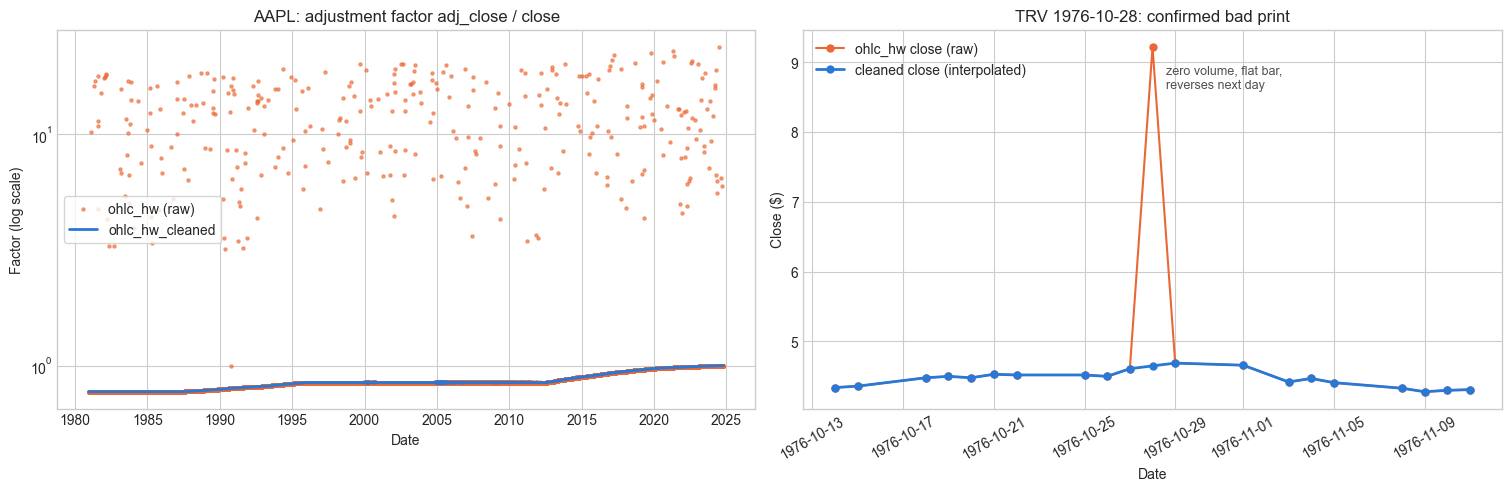

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), layout='constrained')

# Left: AAPL adjustment factor before vs after
ticker = 'AAPL'
before = unique.loc[unique['ticker'] == ticker]
after = ohlc_hw_cleaned.loc[ohlc_hw_cleaned['ticker'] == ticker]
axes[0].scatter(before['ts'], before['adj_close'] / before['close'], s=5, color='#eb6834', alpha=0.6,
                label='ohlc_hw (raw)')
axes[0].plot(after['ts'], after['adj_close'] / after['close'], color='#2a78d6', linewidth=2, label='ohlc_hw_cleaned')
axes[0].set_yscale('log')
axes[0].set(title=f'{ticker}: adjustment factor adj_close / close', xlabel='Date', ylabel='Factor (log scale)')
axes[0].legend(loc='center left', frameon=True, facecolor='white')

# Right: the first confirmed data error, before and after interpolation
error = outlier_review.loc[outlier_review['classification'] == 'confirmed_data_error'].iloc[0]
window = (unique['ticker'] == error['ticker']) & unique['ts'].between(error['ts'] - pd.Timedelta(days=14),
                                                                     error['ts'] + pd.Timedelta(days=14))
fixed = ohlc_hw_cleaned.loc[(ohlc_hw_cleaned['ticker'] == error['ticker'])
                            & ohlc_hw_cleaned['ts'].between(unique.loc[window, 'ts'].min(), unique.loc[window, 'ts'].max())]
axes[1].plot(unique.loc[window, 'ts'], unique.loc[window, 'close'], color='#eb6834', marker='o', markersize=5,
             linewidth=1.5, label='ohlc_hw close (raw)')
axes[1].plot(fixed['ts'], fixed['close'], color='#2a78d6', marker='o', markersize=5, linewidth=2,
             label='cleaned close (interpolated)')
axes[1].annotate('zero volume, flat bar,\nreverses next day', xy=(error['ts'], error['close']),
                 xytext=(10, -30), textcoords='offset points', fontsize=9, color='#52514e')
axes[1].set(title=f"{error['ticker']} {error['ts']:%Y-%m-%d}: confirmed bad print", xlabel='Date', ylabel='Close ($)')
axes[1].legend(loc='upper left')
axes[1].tick_params(axis='x', rotation=30)
plt.show()

In the left panel, the corrupted factors appear as a cloud 4–24× above the true factor. The cleaned factor is a smooth series that steps up at each dividend, as an adjustment factor should. In the right panel, the one-day double print is replaced by an interpolation between the neighbouring sessions.

### Saving to the database

We write to the **local working copy** only:

| Table | Contents |
|---|---|
| `ohlc_hw_cleaned` | Validated rows with repair flags (`*_repaired`, `adj_close_source`), the pre-repair investigation result (`outlier_class`), and the 3σ screen rerun on cleaned prices (`extreme_return_flag`). `ts` is stored as ISO `YYYY-MM-DD` text so the report's SQL filters (`ts >= ? AND ts <= ?`) compare correctly. There is an index on `(ticker, ts)`. |
| `ohlc_hw_quality_report` | The pre-repair Data Quality Report |
| `ohlc_hw_outlier_review` | The extreme-return investigation |
| `ohlc_hw_quarantine` | Quarantined rows, with their reasons |

`if_exists='replace'` makes reruns idempotent. A guard refuses to overwrite either source table.

In [27]:
def to_sql_frame(frame, date_cols):
    out = frame.copy()
    for col in date_cols:
        out[col] = out[col].dt.strftime('%Y-%m-%d')
    return out


outputs = {
    'ohlc_hw_cleaned': to_sql_frame(ohlc_hw_cleaned, ['ts']),
    'ohlc_hw_quality_report': to_sql_frame(quality_report, ['issue_date']),
    'ohlc_hw_outlier_review': to_sql_frame(outlier_review, ['ts']),
    'ohlc_hw_quarantine': to_sql_frame(quarantine_rows[['ticker', 'ts', 'raw_ticker', *ALL_PRICE_COLS, 'volume', 'reason']], ['ts']),
}
assert not {'ohlc', 'ohlc_hw'} & set(outputs), 'Never overwrite the source tables'
with closing(sqlite3.connect(db_path)) as conn:
    for name, frame in outputs.items():
        frame.to_sql(name, conn, if_exists='replace', index=False)
    conn.execute('CREATE INDEX IF NOT EXISTS idx_ohlc_hw_cleaned_ticker_ts ON ohlc_hw_cleaned (ticker, ts)')
    conn.commit()
    saved = {name: conn.execute(f'SELECT COUNT(*) FROM {name}').fetchone()[0] for name in outputs}
    roundtrip = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', conn, parse_dates=['ts'])
    window_rows = conn.execute("SELECT COUNT(*) FROM ohlc_hw_cleaned WHERE ticker = 'AAPL' "
                               "AND ts >= '2024-01-01' AND ts <= '2024-06-30'").fetchone()[0]
    raw_fingerprint_after = table_fingerprint(conn, 'ohlc_hw')
display(pd.Series(saved, name='rows saved').to_frame())

,rows saved
ohlc_hw_cleaned,368245
ohlc_hw_quality_report,113751
ohlc_hw_outlier_review,5056
ohlc_hw_quarantine,6


In [28]:
# Read-back checks: same rows, valid after a round trip, ISO dates, SQL date filters work, raw table untouched.
assert len(roundtrip) == len(ohlc_hw_cleaned)
assert validate_clean(roundtrip)['passed'].all()
assert outputs['ohlc_hw_cleaned']['ts'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()
expected_window = ohlc_hw_cleaned.query("ticker == 'AAPL' and '2024-01-01' <= ts <= '2024-06-30'").shape[0]
assert window_rows == expected_window > 0
assert raw_fingerprint_after == raw_fingerprint, 'ohlc_hw must be unchanged'
print(f'Saved and verified ohlc_hw_cleaned ({len(roundtrip):,} rows) in {db_path.relative_to(course_root)}')
print(f'AAPL rows in 2024-01-01..2024-06-30 via SQL: {window_rows}; ohlc_hw fingerprint unchanged.')

Saved and verified ohlc_hw_cleaned (368,245 rows) in Homeworks/HW2/Farshid_Gilak/data/data.db
AAPL rows in 2024-01-01..2024-06-30 via SQL: 124; ohlc_hw fingerprint unchanged.


## 1.4 Injected-fault tests

Several required cases do not occur in this database: missing raw prices, all-missing rows, `high < close`, non-finite prices, missing and negative volume, conflicting keys, and leading gaps. Following the assignment, we inject each one into a small synthetic dataset where the true values are known. We then run **the same functions** end-to-end and assert the expected detection and repair.

`run_pipeline` chains the steps used above. The synthetic *reference* is the clean truth, and the *delivery* is a dirty copy of it:

| Ticker | Injected faults (session index) |
|---|---|
| DEMO_A | markup label (3), exact duplicate (5), conflicting key (8), **removed date** (12), missing close (15), all-OHLC-missing row (18), `high < close` (21), `open = inf` (24), missing volume (27), negative volume (28), **special dividend** (30, genuine), missing `adj_close` (35), `adj_close` × 10 (40), **+25% genuine move** (50) |
| DEMO_B | leading gap, with the first close missing (0); **double print on zero volume** (20) |
| DEMO_C | a constant price, so the return std is zero |

In [29]:
def run_pipeline(raw_table, reference_table):
    # The full Part 1 pipeline: prepare -> diagnose -> investigate -> clean -> finalize -> validate.
    prepared = prepare(raw_table)
    evidence = reference_evidence(reference_table)
    report, unique, gaps = diagnose(prepared, evidence)
    review = investigate_extreme_returns(unique, evidence)
    clean, removed, quarantine = clean_ohlc(prepared, evidence, review)
    clean = finalize(clean, review)
    return {'report': report, 'unique': unique, 'gaps': gaps, 'review': review, 'clean': clean,
            'removed': removed, 'quarantine': quarantine, 'validation': validate_clean(clean)}


def make_demo_reference(seed=7, sessions=60):
    # Clean synthetic OHLCV with a special dividend (DEMO_A, day 30) and a genuine +25% jump (DEMO_A, day 50).
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range('2024-01-02', periods=sessions)
    frames = []
    for ticker, start in [('DEMO_A', 100.0), ('DEMO_B', 50.0)]:
        log_ret = rng.normal(0, 0.01, sessions)
        log_ret[0] = 0
        if ticker == 'DEMO_A':
            log_ret[50] = np.log(1.25)
        close = start * np.exp(np.cumsum(log_ret))
        factor = np.ones(sessions)
        if ticker == 'DEMO_A':
            close[30:] *= 0.85        # raw price drops on the ex-date...
            factor[:30] = 0.85        # ...and the adjustment factor removes the drop from history
        open_ = close * np.exp(rng.normal(0, 0.003, sessions))
        high = np.maximum(open_, close) * (1 + np.abs(rng.normal(0, 0.004, sessions)))
        low = np.minimum(open_, close) * (1 - np.abs(rng.normal(0, 0.004, sessions)))
        frames.append(pd.DataFrame({'ts': dates.strftime('%Y-%m-%d'), 'open': open_, 'high': high, 'low': low,
                                    'close': close, 'adj_close': close * factor,
                                    'volume': rng.integers(100_000, 1_000_000, sessions), 'ticker': ticker}))
    frames.append(pd.DataFrame({'ts': dates[:8].strftime('%Y-%m-%d'), 'open': 10.0, 'high': 10.0, 'low': 10.0,
                                'close': 10.0, 'adj_close': 10.0, 'volume': 1000, 'ticker': 'DEMO_C'}))
    return pd.concat(frames, ignore_index=True)


demo_reference = make_demo_reference()
truth = demo_reference.set_index(['ticker', 'ts'])
dates = demo_reference.loc[demo_reference['ticker'] == 'DEMO_A', 'ts'].tolist()
day = dict(enumerate(dates))

dirty = demo_reference.copy()
dirty['volume'] = dirty['volume'].astype(float)
at = lambda ticker, i: dirty.index[(dirty['ticker'] == ticker) & (dirty['ts'] == day[i])][0]
dirty.loc[at('DEMO_A', 3), 'ticker'] = '<b> demo_a </b>'
dirty.loc[at('DEMO_A', 15), 'close'] = np.nan
dirty.loc[at('DEMO_A', 18), PRICE_COLS] = np.nan
dirty.loc[at('DEMO_A', 21), 'close'] = dirty.loc[at('DEMO_A', 21), 'high'] * 1.05
dirty.loc[at('DEMO_A', 24), 'open'] = np.inf
dirty.loc[at('DEMO_A', 27), 'volume'] = np.nan
dirty.loc[at('DEMO_A', 28), 'volume'] = -500
dirty.loc[at('DEMO_A', 35), 'adj_close'] = np.nan
dirty.loc[at('DEMO_A', 40), 'adj_close'] *= 10
dirty.loc[at('DEMO_B', 0), 'close'] = np.nan
dirty.loc[at('DEMO_B', 20), PRICE_COLS] *= 2          # double print...
dirty.loc[at('DEMO_B', 20), 'volume'] = 0             # ...on zero volume; adj_close left at its true value
conflict_row = dirty.loc[[at('DEMO_A', 8)]].assign(close=lambda f: f['close'] + 1)
dirty = pd.concat([dirty.drop(index=at('DEMO_A', 12)),        # missing trading day
                   dirty.loc[[at('DEMO_A', 5)]],               # exact duplicate
                   conflict_row], ignore_index=True)
dirty = dirty.sample(frac=1, random_state=11).reset_index(drop=True)   # order must not matter

demo = run_pipeline(dirty, demo_reference)
display(demo['report'].groupby(['issue_type', 'severity']).size().rename('rows').to_frame())
display(demo['review'])
display(demo['quarantine'][['ticker', 'ts', 'close', 'reason']])
display(demo['validation'])

,,rows
issue_type,severity,
adj_close_factor_spike,high,2
adj_close_mismatch_reference,high,1
close_mismatch_reference,high,2
conflicting_duplicate_key,high,2
exact_duplicate,medium,1
extreme_return,medium,4
high_below_close,high,2
invalid_volume,high,1
missing_adj_close,high,1


,ticker,ts,close,volume,return,z_score,classification,action,evidence
0,DEMO_A,2024-02-13,73.929851,795560.0,-0.162907,-3.737967,distribution,keep (corporate action),"Raw close -16.3%, but the reference factor steps +17.6% and persists; adjusted return -1.5% is normal -> dividend/di..."
1,DEMO_A,2024-03-12,91.785594,857694.0,0.250000,5.722534,market_move,"keep, flag","Traded move (volume 857,694); vendor adjusted return +25.0%; cause not verifiable from prices"
2,DEMO_B,2024-01-30,100.775670,0.0,0.992227,6.656786,confirmed_data_error,repair: interpolate OHLC between neighbours,+99.2% one-day jump on zero volume reverses next day (two-day net -2.2%); adjustment factor inconsistent on this dat...
3,DEMO_B,2024-01-31,49.480677,330681.0,-0.509002,-3.509574,error_reversal,resolved by prior-day repair,Bounce back from the previous day's confirmed data error


,ticker,ts,close,reason
0,DEMO_A,2024-01-12,99.605663,conflicting_duplicate_key
1,DEMO_A,2024-01-12,98.605663,conflicting_duplicate_key
2,DEMO_B,2024-01-02,NaN,leading_gap_no_prior_price


,failing_rows,passed
no missing prices (raw + adjusted),0,True
no non-finite prices,0,True
no nonpositive prices,0,True
"unique (ticker, ts) keys",0,True
volume finite and nonnegative,0,True
low <= open <= high,0,True
low <= close <= high,0,True
adjustment factor consistent,0,True
clean tickers (no markup/whitespace),0,True


In [30]:
d, clean = demo, demo['clean'].set_index(['ticker', 'ts'])
ts = lambda i: pd.Timestamp(day[i])
issues = set(d['report']['issue_type'])

# Detection
assert {'ticker_label_markup', 'exact_duplicate', 'conflicting_duplicate_key', 'missing_trading_day',
        'missing_close', 'missing_all_raw_prices', 'high_below_close', 'nonfinite_price', 'missing_volume',
        'invalid_volume', 'missing_adj_close', 'adj_close_factor_spike', 'adj_close_mismatch_reference',
        'extreme_return'} <= issues
gap_rows = d['report'].query("issue_type == 'missing_trading_day'")
assert gap_rows[['ticker', 'issue_date']].values.tolist() == [['DEMO_A', ts(12)]]
assert d['gaps'].set_index('ticker').loc['DEMO_C', 'missing_days'] == 0
status = screen_summary(d['unique'], d['unique'][['return', 'return_flag']])
assert status.loc['DEMO_C', 'status'].startswith('std zero') and status.loc['DEMO_C', 'flagged'] == 0

# Investigation
cls = d['review'].set_index(['ticker', 'ts'])['classification']
assert cls[('DEMO_B', ts(20))] == 'confirmed_data_error' and cls[('DEMO_B', ts(21))] == 'error_reversal'
assert cls[('DEMO_A', ts(30))] == 'distribution' and cls[('DEMO_A', ts(50))] == 'market_move'

# Removal and quarantine
assert d['removed']['reason'].value_counts().to_dict() == {'exact_duplicate': 1, 'all_raw_prices_missing': 1}
assert d['quarantine']['reason'].value_counts().to_dict() == {'conflicting_duplicate_key': 2,
                                                              'leading_gap_no_prior_price': 1}
assert len(dirty) == len(d['clean']) + len(d['removed']) + len(d['quarantine'])

# Repairs: flagged, inside today's range, and adj_close consistent with the trusted factor
for i, col in [(15, 'close'), (21, 'close'), (24, 'open')]:
    row = clean.loc[('DEMO_A', ts(i))]
    assert row[f'{col}_repaired'] and row['low'] <= row[col] <= row['high'], (i, col)
for i in [27, 28]:
    assert clean.loc[('DEMO_A', ts(i)), 'volume'] == 0 and clean.loc[('DEMO_A', ts(i)), 'volume_repaired']
for i in [35, 40]:
    row = clean.loc[('DEMO_A', ts(i))]
    assert row['adj_close_source'] == 'reference_factor'
    assert np.isclose(row['adj_close'], truth.loc[('DEMO_A', day[i]), 'adj_close'])
fixed = clean.loc[('DEMO_B', ts(20))]
neighbours = [truth.loc[('DEMO_B', day[i]), 'close'] for i in (19, 21)]
assert fixed[['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired']].all()
assert np.isclose(fixed['close'], np.mean(neighbours)) and fixed['adj_close_source'] == 'bracketing_factor'
for i in (30, 50):   # genuine events are kept exactly
    assert np.isclose(clean.loc[('DEMO_A', ts(i)), 'close'], truth.loc[('DEMO_A', day[i]), 'close'])
assert d['validation']['passed'].all()
print('All injected-fault tests passed: every fault was detected and repaired, quarantined or kept as documented.')

All injected-fault tests passed: every fault was detected and repaired, quarantined or kept as documented.


## Summary

| Step | Result on `ohlc_hw` |
|---|---|
| Ticker labels | 150 raw labels → 30 tickers (HTML markup removed); originals kept in `raw_ticker` |
| Duplicates | 29,460 exact copies removed; no conflicting keys |
| Missing trading days | 0 for every ticker against its `ohlc` reference calendar (detector demonstrated on a removed date) |
| `adj_close` | ~18k missing and ~10k inflated values rebuilt as `close × trusted factor`. The few vendor-inconsistent factors were bracketed. Every row is flagged with its source. |
| Raw prices | 5 zero opens (first observations) and KO's first row quarantined; confirmed bad TRV prints interpolated; all other raw values kept as delivered |
| Extreme returns | Investigated and classified as data errors, distributions, suspicious reversals, or market moves. Only confirmed errors were changed. The rest are kept and flagged (`outlier_class`, `extreme_return_flag`). |
| Validation | All checks pass; the diagnosis was rerun after cleaning; `ohlc_hw` and `ohlc` are unchanged |

`ohlc_hw_cleaned` is ready for the Part 2 report template, which should read prices from it via `db_path` and use `adj_close` for returns.